### testing imported files given for exercice

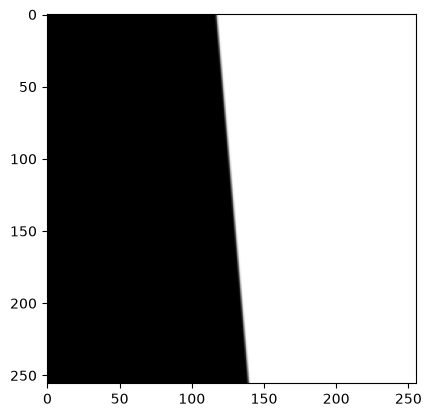

In [8]:
import sfr_lab
import PIL.Image as Image
import numpy as np
import pandas as pd
import colour as color
import matplotlib.pyplot as plt

edge = sfr_lab.render_edge()
plt.imshow(edge, cmap="gray")
plt.show()

# First Exercice

## 1.a present image 
present the image containing the base colour group and the complement colour group:
- red, green, blue
- cian, magenta, yellow

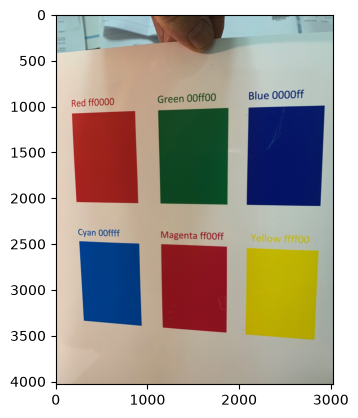

In [9]:
image_dir = "./Printed_Colors.jpeg"
image = Image.open(image_dir)
plt.imshow(image)
plt.show()

We are asked to set rectangles withing the one in the given images such that:
- the rectangle is bounded by the one in the image
- the rectangle covers at least 70% of the one in the image 
for each one in the image.

Method of extraction:
- we will generate a list of coordinates and dimensions for the rectangles
- we will display them over the existing image in black to verify that it indeen covers the correct area.
- we will use the same coordinates to extract the RGB values in the image
- we will average the RGB over the entire RGB array for each of the rectangles

#### Displaying Rectangles

(4032, 3024, 3)
[210 184 159]


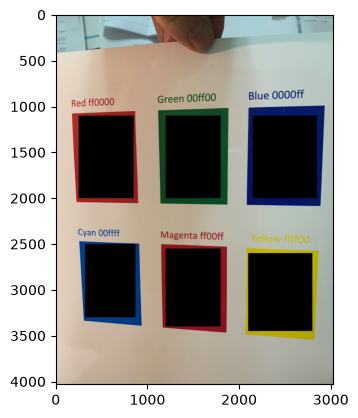

In [10]:
image_as_array = np.asanyarray(image)
pixel_array = image_as_array.copy()

# Check image format
print(pixel_array.shape)
sample_pixel = pixel_array[500, 500]
print(sample_pixel)

# rectangles coordinates 
coordinates = [
    (250, 1100, 600, 900), #Red
    (1200, 1100, 600, 900), #Green
    (2150, 1100, 700, 900), #Blue
     
    (320, 2500, 550, 800), #Cyan
    (1200, 2550, 600, 850), #Magenta
    (2100, 2600, 700, 850), #Yellow
]

# iteration over rectangles coordinates and setting the pixels in the rectangle to black
for x_coord,y_coord,x_span,y_span in coordinates:
    pixel_array[y_coord:y_coord+y_span ,x_coord:x_coord+x_span] = [0, 0, 0]

plt.imshow(pixel_array)
plt.imsave("Printed_Colors_with_black_rectangles.jpeg", pixel_array)

#### Extracting Rectangles

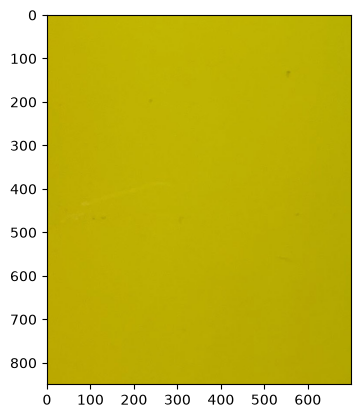

In [11]:
pixel_array = image_as_array.copy()
rectangles = []
mean_pixel_values = []
std_pixel_values = []

for x_coord,y_coord,x_span,y_span in coordinates:
    rectangle = pixel_array[y_coord:y_coord+y_span ,x_coord:x_coord+x_span]
    rectangles.append(rectangle)
    mean_pixel_values.append(np.mean(rectangle, axis=(0, 1)))
    std_pixel_values.append(np.std(rectangle, axis=(0, 1)))

colors = ["red", "green", "blue", "cyan", "magenta", "yellow"]

mean_pixel_values = np.array(mean_pixel_values)
std_pixel_values = np.array(std_pixel_values)

# for checking actual extracted colors = ["red", "green", "blue", "cyan", "magenta", "yellow"]
plt.imshow(rectangles[5])

In [12]:
full_data = np.hstack((mean_pixel_values,std_pixel_values))
full_data.shape
full_data = pd.DataFrame(full_data, columns=["R_mean", "G_mean", "B_mean","R_std", "G_std", "B_std"], index=[color for color in colors])
new_columns=["R_mean", "R_std","G_mean","G_std", "B_mean",  "B_std"]
full_data = full_data[new_columns]
full_data


,R_mean,R_std,G_mean,G_std,B_mean,B_std
red,155.298430,7.071592,33.860081,2.928842,28.043574,2.287675
green,14.581474,3.577792,71.143059,2.353095,35.468554,2.501882
blue,6.082203,2.615654,21.301206,3.398602,100.782414,2.951880
cyan,0.383939,0.520120,59.775802,2.085635,133.485841,4.045394
magenta,137.564073,2.371727,20.056706,2.184423,29.737002,2.445020
yellow,187.865264,3.649103,174.763672,3.846773,1.406832,0.976835


1.a : Questions

**Q - what is the meaning of the std (standard deviation) of the colors?**

A - This means that the color of every rectangle in the image is not completely uniform. This was expected for a few reasons:

    - The lighting is warmer closer to the red rectangle and darker in other regions in the image which explains the reasonably high std for red (7.07).
    - We can see some smears in the ink and abnormalites in some rectangles that lessen the uniformity of the colors
    - Some parts of the paper in the image are a bit reflective which adds white light into the averaging of the colors.

**Q - How can we explain the change between the original colors and the measured ones?**

A - The measured RGB values differ from the original ones because the image was printed and then photographed. This process     introduces several changes:

    - The printer's ink and paper cannot reproduce the exact original RGB colors.
    - The lighting conditions affect how the colors appear in the photograph.
    - The camera's sensor, white balance and image processing can change the recorded RGB values.
    - Reflections from the paper can also affect the measured colors.

**Q - Can we conclude why industry standard printing uses complementary colors instead of RGB?**

A - Printing uses the complementary colors Cyan, Magenta, and Yellow because it works with a subtractive color model, unlike screens that use an additive RGB model. Screens produce colors by combining red, green, and blue light, while printed paper reflects light and the inks absorb specific wavelengths. Cyan absorbs red light, Magenta absorbs green light, and Yellow absorbs blue light. By combining these inks in different amounts, a wide range of colors can be produced. Black ink (K) is also added in CMYK printing to achieve deeper blacks and improve printing efficiency.



# 1.b Explaining what is the XYZ colourspace

given a colour with components $[R,G,B]$ in sRGB colourspace the $[X,Y,Z]$ components are given by by the formula : <br>

$X = 0.49 \cdot R + 0.31 \cdot G + 0.2 \cdot B$<br>

$Y = 0.177 \cdot R + 0.812 \cdot G + 0.011 \cdot B$<br>

$Z = 0 \cdot R + 0.01 \cdot G + 0.99 \cdot B$<br>

*(as presented in the lecture notes - Lecture 1, slide 38 ...)*

NOT FINISHED!!!

## 1.c Converting to XYZ values

For this exercise we will use the colour-science library and use its built in function for that conversion

In [13]:
xyz_values = np.zeros_like(full_data[["R_mean", "G_mean", "B_mean"]].values)

for i, row in enumerate(full_data[["R_mean", "G_mean", "B_mean"]].values):
    # Encoded sRGB values in range [0, 1]
    rgb = row / 255.0
    # Decode transfer function (gamma/OETF) and transform to CIE XYZ
    xyz = color.RGB_to_XYZ(
        rgb,
        colourspace="sRGB",
        apply_cctf_decoding=True,
    )
    xyz_values[i] = xyz

xyz_values = pd.DataFrame(xyz_values, columns=["X", "Y", "Z"], index=[color for color in colors])
xyz_values


AttributeError: module 'colour' has no attribute 'RGB_to_XYZ'

In addition we will add for reference the 6 original colours according to their definition

Text(0.5, 1.0, 'Original colors (top) vs extracted colors (bottom)')

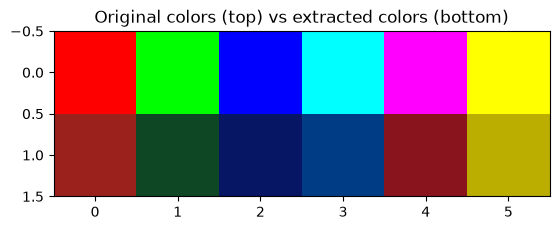

In [14]:
R = [255, 0, 0]
G = [0, 255, 0]
B = [0, 0, 255]

Y = [255, 255, 0]
C = [0, 255, 255]
M = [255, 0, 255]


R_mean = mean_pixel_values[0]
G_mean = mean_pixel_values[1]
B_mean = mean_pixel_values[2]

Y_mean = mean_pixel_values[3]
C_mean = mean_pixel_values[4]
M_mean = mean_pixel_values[5]

# Original colors - uncomment the following line to see the original colors
# plt.imshow(np.array([[R, G, B], [Y, C, M]]).astype(np.uint8))

# Mean colors - uncomment the following line to see the mean colors extracted from the rectangles
# plt.imshow(np.array([[R_mean, G_mean, B_mean], [Y_mean, C_mean, M_mean]]).astype(np.uint8))

plt.imshow(np.array([[R, G, B, C, M , Y],[R_mean, G_mean, B_mean, Y_mean, C_mean, M_mean]]).astype(np.uint8))
plt.title("Original colors (top) vs extracted colors (bottom)")

## 1.d Explaining projection from XYZ to xy plane of the CIE diagram

TODO

## 1.e Projecting all 12 colours from XYZ to xy plane of the CIE diagram

TODO

# Second Exercice


## Part 1: Implement and Validate

In experiment A we run our `sfr()` on the 5° edge without noise and compare the measured MTF with the exact (true) MTF.

![Figure A](fig_A_validation.png)

*Figure A – From left to right: the test edge, the ESF, the LSF, and the measured MTF compared with the true MTF (red line: the error × 20).*

**Validation result:** the largest error up to Nyquist is **0.0033** (must be below 0.01). The measured MTF50 is **0.2812** and the true one is 0.2807, so the difference is **0.0004** (must be below 0.002). Both conditions are met, so our implementation passes the check.

**Q1.1 – Why is the Hamming window centered on the LSF peak and not on the middle of the array?**

**A1.1:** The Hamming window is centered on the LSF peak because the peak represents the location of the strongest intensity change across the edge.
Centering the window on the peak preserves the most important part of the LSF while reducing the influence of its edges and minimizing spectral leakage during the FFT.
If the window were centered on the middle of the array, the LSF peak might receive a lower weight, potentially distorting the measured MTF.

**Q1.2 – What happens to the measured MTF if you skip the derivative correction? At which frequencies does it matter?**

**A1.2:** The central difference method used to calculate the LSF introduces attenuation, particularly at higher spatial frequencies.
Without the derivative correction, the measured MTF would underestimate the true MTF because of the additional attenuation introduced by the numerical derivative.
The correction compensates for this effect by dividing the measured MTF by the frequency response of the central difference filter, sinc(2f·bw), where bw = 0.25 pixels.
At low frequencies, the correction has very little effect because the sinc function is close to 1. However, as the frequency increases, the attenuation becomes more significant.
Therefore, the derivative correction is especially important near the Nyquist frequency (0.5 cycles/pixel) and at higher spatial frequencies.

**Q1.3 – Pass a uint8 image to your sfr() without converting it to float. What goes wrong, and why?**

**A1.3:** The uint8 data type represents unsigned 8-bit integers in the range 0–255.
When performing arithmetic operations such as subtraction directly on uint8 arrays, negative results cannot be represented correctly and may wrap around.
For example, subtracting 200 from 50 should produce -150, but with uint8 arithmetic, the result becomes 106.
This can produce incorrect intensity differences, distort the edge detection process, and lead to inaccurate ESF, LSF, and MTF measurements.
In our implementation, both sfr() and edge_fit() convert the input image to float before these calculations, so a uint8 image works correctly. To see what goes wrong without this conversion, we removed it and ran the test below.

**Our test (code cell below):** we took the 8-bit edge with noise (σn = 2 DN) and ran `sfr()` twice: once normally, and once after removing the conversion to float.

| | float conversion (correct) | uint8, no conversion |
|---|---|---|
| fitted edge angle | 5.00° | **−3.98°** |
| MTF50 [cy/px] | 0.2769 | **0.0290** |

**Why it fails:** `edge_fit()` looks for the edge in every row using `np.diff` (the difference between neighbouring pixels). With float, these differences are between −13 and +90. uint8 cannot store negative numbers, so a small negative difference like −1 becomes 255. Now the noise looks like a huge jump, bigger than the real edge, and the code finds the edge in the wrong place in many rows. The fitted line is wrong (−3.98° instead of 5°), so the ESF is built around the wrong line, it gets smeared, and the MTF drops a lot (MTF50 is about 10 times too low). This is why the code converts the image to float first.

**Q1.4 – Explain in the code comments all lines of the working sfr_lab.py. What is the purpose of the following line in the edge_fit() function?**

**xc[r] = (w * xs[lo:hi]).sum() / w.sum()**

**A1.4:** This line calculates the weighted centroid of the intensity derivative around the detected edge in row r.
The array w contains the derivative magnitudes within a window around the detected edge, while xs[lo:hi] contains the corresponding horizontal positions.
Each position is multiplied by its derivative magnitude, and the sum of these weighted positions is divided by the total sum of the weights.
This provides a sub-pixel estimate of the edge location, rather than simply selecting the position with the maximum derivative.
The weighted centroid also helps reduce sensitivity to small local intensity fluctuations caused by noise, resulting in a more stable edge position estimate.
This accurate edge localization is important for constructing the oversampled ESF and obtaining reliable MTF measurements

In [ ]:
# Q1.3 experiment: pass a uint8 image to sfr() with and without the float conversion
import numpy as np
import sfr_lab as L

# 8-bit noisy edge (5 deg, sigma = 0.6 px, noise 2 DN, fixed seed 0)
img = L.to_uint8(L.add_noise(L.render_edge(), 2, seed=0))

# 1) the working sfr(): it converts the image to float internally
f, m, info = L.sfr(img)
print(f"float (correct):  angle = {info['angle_deg']:.2f} deg, MTF50 = {L.mtf50(f, m):.4f} cy/px")

# np.diff (used in edge_fit) on uint8 vs float: negative differences wrap around in uint8
d_u8, d_f = np.diff(img, axis=1), np.diff(img.astype(float), axis=1)
print(f"np.diff on uint8: min = {d_u8.min()}, max = {d_u8.max()}   (float: min = {d_f.min():.0f}, max = {d_f.max():.0f})")

# 2) a copy of sfr_lab with the float conversions removed (sfr_lab.py itself is not changed)
src = open('sfr_lab.py').read().replace('img = np.asarray(img, dtype=float)', 'img = np.asarray(img)')
ns = {}
exec(compile(src, 'sfr_lab_no_cast', 'exec'), ns)
f2, m2, info2 = ns['sfr'](img)
print(f"uint8 (no cast):  angle = {info2['angle_deg']:.2f} deg, MTF50 = {ns['mtf50'](f2, m2):.4f} cy/px")

float (correct):  angle = 5.00 deg, MTF50 = 0.2769 cy/px
np.diff on uint8: min = 0, max = 255   (float: min = -13, max = 90)
uint8 (no cast):  angle = -3.98 deg, MTF50 = 0.0290 cy/px


## Part 2: Edge angle

In experiment B we measure the same edge without noise at 11 different angles, from 0° to 45°. For each angle we check the largest MTF error up to Nyquist and count how many ¼-pixel bins stayed empty.

![Figure B](fig_B_angle.png)

*Figure B – Largest MTF error vs. edge angle (log scale). The number above each point is how many bins were empty (out of 192).*

**What the figure shows:** at 1°, 2°, 5°, 10°, 22°, 30° and 40° there are no empty bins and the error is small (about 0.002). At 0°, 18.43°, 26.57° and 45° some bins are empty (144, 26, 74 and 121) and the error is much bigger (0.030 to 0.109, about 15–55 times more). So the error comes from the empty bins, which are filled by interpolation instead of real data.

**Q2.1 – Why does the method fail at 0°?**

**A2.1:** At 0°, the edge is perfectly vertical, meaning that every image row samples the edge at the same sub-pixel positions.
As a result, combining the rows does not provide additional sampling positions, and many ESF bins remain empty.
In our experiment, 144 empty bins were detected, resulting in a maximum MTF error of 0.10936.
Therefore, the method cannot accurately reconstruct the oversampled ESF, leading to significant errors in the measured MTF.

**Q2.2 – The error rises sharply at 18.43° (tanθ = 1/3), 26.57° (tanθ = 1/2), and 45° (tanθ = 1). Explain why, using the set of distances that pixel centers can have from the edge.**

**A2.2:** At these angles, the tangent of the edge angle is a simple rational number, causing the perpendicular distances of pixel centers from the edge to repeat in a discrete pattern.
The perpendicular distance is calculated as:
d = (x - ay - b) / sqrt(1 + a²)
where a = tan(θ).
For example, at 45°, where a = 1, the distances are proportional to integer values of x - y. Therefore, the possible distances are separated by approximately 0.707 pixels, which is larger than our ESF bin width of 0.25 pixels.
Similarly, the distance spacing is approximately 0.316 pixels at 18.43° and 0.447 pixels at 26.57°.
This causes many pixels to fall into the same bins while other bins remain empty.
In our experiment, we observed 26, 74, and 121 empty bins at 18.43°, 26.57°, and 45°, respectively.
These empty bins require interpolation, introducing errors into the ESF reconstruction and increasing the measured MTF error.

**Q2.3 – ISO 12233 recommends an angle of about 5°. What limits the angle from above, in a real measurement?**

**A2.3:** The limit is not the empty bins – Fig. B shows that 22°, 30° and 40° work as well as 5°. The limit comes from a real camera and lens:

1. **We want the horizontal MTF.** The method measures the MTF in the direction perpendicular to the edge. At 5° this direction is almost horizontal, so we get the horizontal MTF of the camera, which is what ISO 12233 asks for. At a large angle the direction is diagonal and mixes the horizontal and vertical MTF. You can see this in the true MTF formula, sinc(f·cosθ)·sinc(f·sinθ): at 5° the second sinc is almost 1, but at 45° both are equal. In a real camera the horizontal and vertical MTF are often different, so a large angle gives a value that is neither of them.
2. **The lens is not the same everywhere.** A steep edge crosses a wide part of the image, where the lens can be sharper or blurrier and can bend straight lines, so the edge is no longer a straight line. A bigger ROI is also needed.
3. **Finding the edge gets harder.** `edge_fit()` finds the edge separately in every row. When the angle is large, the edge looks wider in each row, so its position is less accurate.

About 5° is a good compromise: small enough to measure the horizontal MTF, but big enough that the edge moves about 22 pixels over the 256 rows (256·tan 5°), so all the ¼-pixel bins get filled (0 empty bins, error 0.0033).

## Part 3: Noise

Experiment C adds white Gaussian noise of σn = 0, 1, 2, 4 and 8 DN to the 8-bit 5° edge (step of 153 DN) and repeats every level with the same 30 seeds. Fig. C shows the mean MTF ± 1 std (left) and the mean MTF50 with error bars together with the noise floor, i.e. the mean MTF from 0.6 to 1 cycle/pixel (right).

![Figure C](fig_C_noise.png)

*Figure C – Left: mean MTF ± 1 std over 30 seeds for each noise level. Right: mean MTF50 ± 1 std (blue, left axis) and the noise floor (red, right axis) vs. σn.*

**What the figure shows:** on the left, all the MTF curves follow the true MTF up to about 0.4 cycles/pixel, but above that the noisy curves stay higher than the truth, and the higher the noise, the higher they go. On the right, MTF50 stays close to the true value (dashed line) while its error bars grow with the noise, and the noise floor (red) rises from 0.012 at σn = 0 to 0.066 at σn = 8.

**Q3.1 – Does noise bias MTF50, or only make it more uncertain? Support your answer with the numbers in results.json.**

**A3.1:** Noise mostly makes MTF50 less certain, and it barely biases it.

Results from results.json (true MTF50 = 0.2807):

| σn [DN] | mean MTF50 | std (30 seeds) |
|---|---|---|
| 0 | 0.2809 | 0 |
| 1 | 0.2801 | 0.0009 |
| 2 | 0.2798 | 0.0016 |
| 4 | 0.2794 | 0.0031 |
| 8 | 0.2792 | 0.0063 |

The mean stays very close to the true value: from σn = 0 to σn = 8 it goes down by only 0.0018 (about 0.6%).
The std, on the other hand, grows a lot – it is 7 times larger at σn = 8 than at σn = 1.
At σn = 8 the shift of the mean (0.0015 from the true value) is about 4 times smaller than the std (0.0063), and in Fig. C the true value is inside the error bars at every noise level from σn = 1 up.
So the main effect of noise is random error, not bias.

The small downward shift probably comes from the edge fit: noise moves the edge position found in each row a little, so the fitted line is slightly off. This smears the ESF a bit, like extra blur, which lowers the MTF slightly.

**Q3.2 – How does the standard deviation of MTF50 scale with σn? Is that what you expect?**

**A3.2:** The std of MTF50 grows linearly with σn – when the noise doubles, the std about doubles:

| σn [DN] | std of MTF50 | ratio to previous level |
|---|---|---|
| 1 | 0.00089 | – |
| 2 | 0.00160 | 1.79 |
| 4 | 0.00314 | 1.97 |
| 8 | 0.00628 | 2.00 |

This is what we expect. The noise is small compared to the edge step (153 DN), so it only causes small changes in the ESF, LSF and MTF, and small changes are proportional to the noise that causes them. Also, because every noise level uses the same 30 seeds, the noise at σn = 8 is exactly twice the noise at σn = 4, so if the effect is linear the std should double exactly – and it does (2.00). At σn = 1 the ratio is a bit lower (1.79), because the 8-bit rounding (steps of 1 DN) is about as large as the noise itself, so the rounding changes the noise and the scaling is no longer exact.

**Q3.3 – Why does noise raise the MTF at high frequencies instead of lowering it?**

**A3.3:** Without noise, the true MTF above 0.6 cycles/pixel is almost zero. White noise has the same strength at all frequencies, so it adds a contribution at high frequencies as well. The MTF is the magnitude |FFT|, which is always positive, so the noise cannot cancel out: where the real signal is almost zero, we just measure the size of the noise, which is always above zero. On top of that, the derivative (ESF → LSF) makes high frequencies stronger, and the derivative correction divides by sinc(2f·bw) < 1, which boosts the high-frequency noise even more. This is why the noise floor goes up with the noise: 0.012, 0.014, 0.020, 0.035 and 0.066 for σn = 0, 1, 2, 4 and 8.

**Q3.4 – Name two ways to reduce the noise floor in a real measurement, and explain each in terms of the number of samples per ESF bin.**

**A3.4:** Each ¼-pixel ESF bin is the average of the pixels that fall into it. In our 256 × 256 image that is about N = 64 pixels per bin (256 rows, 4 bins per pixel). Averaging N samples reduces the noise in the bin to σn/√N, so more samples per bin means a cleaner ESF and a lower noise floor.

1. **Use a longer edge (a taller ROI).** More rows means more pixels in every bin. Twice as many rows gives N = 128 and lowers the noise in each bin by √2. The limit is that the edge must stay straight and the lens must be similar along it.
2. **Average several images of the same edge.** With M images, every bin gets M·N samples (the same as averaging the frames first, which lowers σn to σn/√M). For example, 4 images cut the noise in each bin in half.

(Wider bins, i.e. less oversampling, would also put more samples in each bin, but then we lose the high frequencies we wanted to measure.)

## Part 4: JPEG compression

In experiment D we compress the 8-bit edge with Pillow's JPEG at Q = 100, 95, 90, 75, 50, 30, 20, 10 and 5, decode it and measure the MTF. We do this twice: on the clean image and on the same image with σn = 2 DN noise (seed 0).

![Figure D](fig_D_jpeg.png)

*Figure D – Left: MTF of the decoded clean image for every Q. Middle: MTF50 vs. bits per pixel (log scale). Right: MTF50 vs. Q. Blue = clean, orange = σn = 2 DN.*

**What the figure shows:** from Q = 100 down to about Q = 75 the MTF is almost the same as the truth. Below that the high frequencies drop first, and at Q ≤ 20 the whole curve changes. MTF50 does not go down smoothly with Q – it jumps up at Q = 30 and down again at Q = 20. The noisy image needs many more bits at high Q, but at low Q both images need about the same number of bits.

**Q4.1 – Which frequencies does JPEG remove first as Q falls? Relate this to the DCT quantization table.**

**A4.1:** JPEG removes the highest frequencies first. The MTF at Nyquist (0.5 cycles/pixel, true value 0.108) is 0.114 at Q = 100 and 0.112 at Q = 90, but drops to 0.030 at Q = 75 and to 0.001 at Q = 50. A middle frequency like 0.3 cycles/pixel (true value 0.453) is still 0.445 at Q = 75 and only really drops at Q ≤ 20 (0.198 at Q = 20).

The reason is the quantization table. JPEG splits the image into 8×8 blocks, takes the DCT of each block, and divides every DCT coefficient by a step from the table, then rounds. The steps are small for low frequencies and large for high frequencies, and a lower Q makes all the steps bigger. For example, in Pillow's table the steps go from 2 to 24 at Q = 90, from 10 to 121 at Q = 50, and from 17 to 201 at Q = 30. A coefficient that is smaller than half of its step is rounded to zero, so as Q falls the high-frequency coefficients (which are small and have the largest steps) are the first to become zero.

**Q4.2 – MTF50 is not monotonic in Q (look at Q = 30). Look at the MTF curves and the decoded images and explain how compression can make an edge look sharper by MTF50.**

**A4.2:** At Q = 30 the measured MTF50 is 0.287, higher than the true value (0.2807) and higher than at Q = 50 (0.272). The noisy image shows the same jump (0.284), so it comes from the compression and not from the noise. In Fig. D (left) the Q = 30 curve goes slightly above the truth between about 0.1 and 0.35 cycles/pixel (by up to 0.016; at 0.3 cycles/pixel it is 0.461 instead of 0.453), so it crosses 0.5 later.

Removing high frequencies by itself can only make the edge blurrier (that is what happens at Q = 50), so the jump must come from something else. The decoded image shows what (code cell below): when JPEG throws away high-frequency DCT coefficients, the edge gets *ringing* – a small overshoot on the light side and an undershoot on the dark side of the edge (about 1.5% and 1.2% of the step at Q = 30). The LSF then gets negative side lobes (−9% of its peak). An edge with overshoot on both sides is exactly what a sharpening filter does, and sharpening boosts the middle frequencies – so MTF50 goes up.

It is not monotonic because which coefficients are rounded up, down or to zero changes in jumps when Q changes. At Q = 50 the high-frequency loss wins (MTF50 is lower), at Q = 30 the ringing happens to boost the frequencies around MTF50, and at Q = 20 so much is removed that MTF50 drops to 0.242. So a higher MTF50 here does not mean a better image: the error compared with the clean image is 1.88 DN at Q = 30 vs. 1.03 DN at Q = 50.

**Q4.3 – At Q = 100 the noisy image needs about 12× more bits than the clean one. Why? What happens to the noise at Q ≤ 50?**

**A4.3:** At Q = 100 the clean image needs 0.31 bpp and the noisy one 3.72 bpp (11.9×). The clean edge is very smooth, so almost all of its DCT coefficients are zero and cost almost nothing. Noise is random, so it puts a little energy into every DCT coefficient of every block. At Q = 100 all the steps are 1, so all of this noise is kept and has to be coded, and random values cannot be compressed well.

At Q = 90 the steps are still small (2 to 24), so only part of the noise is removed: the noisy image still needs 3.8× more bits (0.880 vs. 0.230 bpp) and its error compared with the clean image is still 1.51 DN.

At Q ≤ 50 the steps are at least 10, while the noise in each DCT coefficient is only about 2 DN. Almost all noise coefficients are smaller than half a step, so they are rounded to zero – JPEG removes the noise. That is why at Q = 50 the noisy image needs almost the same bits as the clean one (0.188 vs. 0.177 bpp), and its error compared with the clean image drops from 2.08 DN at Q = 100 to 1.09 DN at Q = 50 – less than the noise we added.

**Q4.4 – Above about 0.6 cycles/pixel, the JPEG curves show bumps that are not in the ground truth. Where do they come from?**

**A4.4:** The bumps come from JPEG's 8×8 blocks. The ringing and the small jumps at block borders (blocking) depend on where the edge falls inside the block. Because the edge is slanted, it moves across the 8-pixel block grid from row to row, so the error is different in every row, but it repeats with the 8-pixel block period. When all rows are combined into one oversampled ESF, these errors do not average out like random noise does – they add up into a fixed pattern in the ESF. This pattern has high-frequency content, so it appears as bumps in the MTF. Some of the bumps are close to multiples of 1/8 cycles/pixel (for example 0.625, 0.75 and 0.875 at Q = 30), which points to the 8-pixel block grid. The lower the Q, the stronger the artifacts and the bigger the bumps: the highest bump above 0.6 cycles/pixel is 0.12 at Q = 30, 0.18 at Q = 10 and 0.20 at Q = 5, while the true MTF there is below 0.01.

In [ ]:
# Q4.2 / Q4.4 check: what JPEG does to the edge at different Q (clean 8-bit image)
import numpy as np
import sfr_lab as L
from scipy.signal import find_peaks

clean = L.render_edge()                      # 5 deg edge, dark = 51, light = 204
base = L.to_uint8(clean)
FF = np.linspace(0, 1, 401)
truth = L.true_mtf(FF, 0.6, 5)

for q in [75, 50, 30, 20]:
    dec, bpp = L.jpeg(base, q)               # compress + decode
    f, m, info = L.sfr(dec)                  # measure the MTF of the decoded image
    mtf = np.interp(FF, f, m)
    esf, lsf = info['esf'], info['lsf']
    overshoot = (esf.max() - 204) / 153 * 100     # % above the light level
    undershoot = (51 - esf.min()) / 153 * 100     # % below the dark level
    side_lobe = lsf.min() / lsf.max() * 100       # negative LSF lobe, % of the peak
    peaks, _ = find_peaks(mtf * (FF > 0.55), prominence=0.01)   # bumps above 0.55 cy/px
    print(f'Q={q:3d}: MTF50={L.mtf50(f, m):.3f}, overshoot={overshoot:.1f}%, undershoot={undershoot:.1f}%, '
          f'LSF side lobe={side_lobe:.0f}%, MTF(0.3)={np.interp(0.3, FF, mtf):.3f} (true {np.interp(0.3, FF, truth):.3f}), '
          f'bumps at {np.round(FF[peaks], 3)} cy/px')

Q= 75: MTF50=0.278, overshoot=0.5%, undershoot=0.6%, LSF side lobe=-5%, MTF(0.3)=0.445 (true 0.453), bumps at [0.688] cy/px
Q= 50: MTF50=0.272, overshoot=1.2%, undershoot=0.9%, LSF side lobe=-6%, MTF(0.3)=0.404 (true 0.453), bumps at [0.562 0.665 0.75 ] cy/px
Q= 30: MTF50=0.287, overshoot=1.5%, undershoot=1.2%, LSF side lobe=-9%, MTF(0.3)=0.461 (true 0.453), bumps at [0.625 0.728 0.875 0.96 ] cy/px
Q= 20: MTF50=0.242, overshoot=2.7%, undershoot=2.7%, LSF side lobe=-11%, MTF(0.3)=0.198 (true 0.453), bumps at [0.552 0.728 0.832] cy/px
